In [75]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [76]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax
import copy

from typing import Callable

from functools import partial

import tensorflow as tf
from pyDOE import lhs
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import odeint
from scipy.special import erf

from jax import config
config.update("jax_enable_x64", True)

In [77]:
units_num = 10

In [78]:
t0, tfinal = 0.0, 0.5

In [79]:
m1 = 1.0
m2 = 1.0
l1 = 1.0
l2 = 1.0
grav = 9.81

In [80]:
def doublePendulum(w, t):
    
    x1, x2, y1, y2 = w
    
    A = l1*l2*(m1 + m2*(jnp.sin(x1 - x2)**2))
    h1 = (y1*y2*jnp.sin(x1 - x2))/A
    h2 = (m2*(l2**2)*(y1**2) + (m1 + m2)*(l1**2)*(y2**2) - 2*m2*l1*l2*y1*y2*jnp.cos(x1 - x2))/(2*A**2)

    x1_t = (l2*y1 - l1*y2*jnp.cos(x1 - x2))/(l1*A)
    x2_t = (-m2*l2*y1*jnp.cos(x1 - x2) + l1*(m1 + m2)*y2)/(m2*l2*A)
    y1_t = -(m1 + m2)*grav*l1*jnp.sin(x1) - h1 + h2*jnp.sin(2*(x1 - x2))
    y2_t = -m2*grav*l2*jnp.sin(x2) + h1 - h2*jnp.sin(2*(x1 - x2))

    dwdt = [x1_t, x2_t, y1_t, y2_t]

    return dwdt

In [81]:
class Normalize(nn.Module):
  xmin: float
  xmax: float

  @nn.compact
  def __call__(self, x):
    return 2.0*(x-self.xmin)/(self.xmax - self.xmin) - 1.0

In [82]:
class HardConstraint(nn.Module):
  t0: float
  tfinal: float
  u0: float

  @nn.compact
  def __call__(self, inputs):
    t, nn = inputs
    return self.u0 + (t-self.t0)/(self.tfinal-self.t0)*nn

In [83]:
class CombineBranches(nn.Module):
  @nn.compact
  def __call__(self, inp1, inp2):
    mult = jnp.sum(inp1*inp2, axis=1)
    out = jnp.reshape(mult, (-1,1))
    return out

In [84]:
class MLP(nn.Module):

  layers: int
  units: int

  @nn.compact
  def __call__(self, inp):
    b = inp
    for i in range(self.layers-1):
      b = nn.Dense(self.units)(b)
      b = nn.tanh(b)
    out = nn.Dense(4*self.units)(b)
    return out

In [85]:
class DeepONet(nn.Module):

  t0: float
  tfinal: float
  layers: int
  units: int

  @nn.compact
  def __call__(self, t, u):

    if u.ndim == 1:
      u = jnp.reshape(u, (1,-1))

    x1_0 = u[:,:1]
    x2_0 = u[:,1:2]
    y1_0 = u[:,2:3]
    y2_0 = u[:,3:]

    t = jnp.reshape(t, (-1,1))

    b = Normalize(self.t0, self.tfinal)(t)

    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(u)

    trunk_x1 = trunk_net[:,:self.units]
    trunk_x2 = trunk_net[:,self.units:2*self.units]
    trunk_y1 = trunk_net[:,2*self.units:3*self.units]
    trunk_y2 = trunk_net[:,3*self.units:]

    branch_x1 = branch_net[:,:self.units]
    branch_x2 = branch_net[:,self.units:2*self.units]
    branch_y1 = branch_net[:,2*self.units:3*self.units]
    branch_y2 = branch_net[:,3*self.units:]

    x1 = CombineBranches()(trunk_x1, branch_x1)
    x2 = CombineBranches()(trunk_x2, branch_x2)
    y1 = CombineBranches()(trunk_y1, branch_y1)
    y2 = CombineBranches()(trunk_y2, branch_y2)

    x1 = HardConstraint(self.t0, self.tfinal, x1_0)([t, x1])
    x2 = HardConstraint(self.t0, self.tfinal, x2_0)([t, x2])
    y1 = HardConstraint(self.t0, self.tfinal, y1_0)([t, y1])
    y2 = HardConstraint(self.t0, self.tfinal, y2_0)([t, y2])

    x1 = jnp.reshape(x1, (-1,))
    x2 = jnp.reshape(x2, (-1,))
    y1 = jnp.reshape(y1, (-1,))
    y2 = jnp.reshape(y2, (-1,))

    return x1, x2, y1, y2

In [86]:
deeponet = DeepONet(t0, tfinal, layers=4, units=units_num)

params = deeponet.init(jax.random.PRNGKey(0), jnp.ones((10,)), jnp.ones((10,4)))

In [87]:
def defineCollocationPoints(t_bdry, N=100):

  ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N)

  xs = np.random.uniform(-np.pi/6, np.pi/6, size=(N, 2))
  ys = np.random.uniform(-np.pi/6, np.pi/6, size=(N, 2))

  zsensors = np.column_stack((xs, ys))

  return (ode_points, zsensors)

In [88]:
(de_points, zsensors) = defineCollocationPoints([t0, tfinal], 500)

In [89]:
@partial(jax.jit, static_argnums=(2,))
def w_model(t, z, component, params):
  return deeponet.apply(params, t, z)[component][0]

@partial(jax.jit, static_argnums=(2,))
def w(t, z, component, params):
  return jax.vmap(w_model, [0, 0, None, None])(t, z, component, params)

@partial(jax.jit, static_argnums=(2,))
def w_t(t, z, component, params):
  return jax.vmap(jax.grad(w_model, 0), [0, 0, None, None])(t, z, component, params)

@jax.jit
def loss(params, t, z):

    x1 = w(t, z, 0, params)
    x2 = w(t, z, 1, params)
    y1 = w(t, z, 2, params)
    y2 = w(t, z, 3, params)
    
    x1_t = w_t(t, z, 0, params)
    x2_t = w_t(t, z, 1, params)
    y1_t = w_t(t, z, 2, params)
    y2_t = w_t(t, z, 3, params)
    
    
    A = l1*l2*(m1 + m2*(jnp.sin(x1 - x2)**2))
    h1 = (y1*y2*jnp.sin(x1 - x2))/A
    h2 = (m2*(l2**2)*(y1**2) + (m1 + m2)*(l1**2)*(y2**2) - 2*m2*l1*l2*y1*y2*jnp.cos(x1 - x2))/(2*A**2)
    
    x1_t_loss = x1_t - (l2*y1 - l1*y2*jnp.cos(x1 - x2))/(l1*A)
    x2_t_loss = x2_t - (-m2*l2*y1*jnp.cos(x1 - x2) + l1*(m1 + m2)*y2)/(m2*l2*A)
    y1_t_loss = y1_t - (-(m1 + m2)*grav*l1*jnp.sin(x1) - h1 + h2*jnp.sin(2*(x1 - x2)))
    y2_t_loss = y2_t - (-m2*grav*l2*jnp.sin(x2) + h1 - h2*jnp.sin(2*(x1 - x2)))

    diff_loss = jnp.mean(x1_t_loss**2 + x2_t_loss**2 + y1_t_loss**2 + y2_t_loss**2)

    return diff_loss

@jax.jit
def train_step(params, pdes, z):
  t = pdes[:,0]
  return jax.value_and_grad(loss)(params, t, z)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

In [90]:
def train_network(params, des, zsensor, epochs=100):

  N = de_points.shape[0]

  nr_batches = 10
  batch_size = len(des)//nr_batches

  lr = 1e-3
  optimizer = optax.adam(lr)
  opt_state = optimizer.init(params)

  ds_z = tf.data.Dataset.from_tensor_slices(zsensors)
  ds_de = tf.data.Dataset.from_tensor_slices(des)

  ds = tf.data.Dataset.zip((ds_de, ds_z))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.zeros(epochs)

  for i in range(epochs):

    for (des_batch, z_batch) in ds:

      loss, grads = train_step(params, des_batch.numpy(), z_batch.numpy())
      params, opt_state = optimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    if i % 500 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [91]:
epochs = 2500
params, loss = train_network(params, de_points, zsensors, epochs)

Loss in epoch 0: 7.793158868504538
Loss in epoch 500: 0.015707904362552955
Loss in epoch 1000: 0.012719869172803109
Loss in epoch 1500: 0.009035892754702632
Loss in epoch 2000: 0.007409486475763548


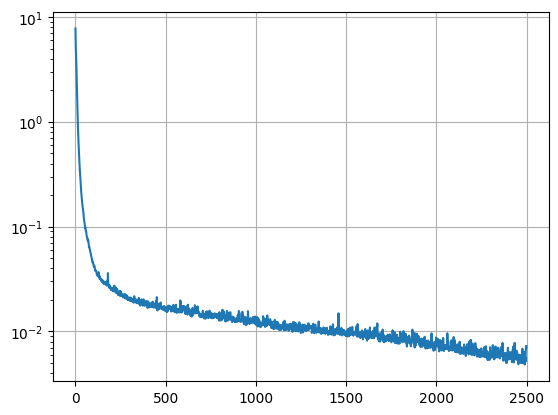

In [92]:
plt.semilogy(loss)
plt.grid()

In [93]:
n = 10
t = np.linspace(t0, tfinal, n)

x1_data = np.random.uniform(-np.pi/6, np.pi/6, size=(1,))
x2_data = np.random.uniform(-np.pi/6, np.pi/6, size=(1,))
y1_data = np.random.uniform(-np.pi/6, np.pi/6, size=(1,))
y2_data = np.random.uniform(-np.pi/6, np.pi/6, size=(1,))
H_data = (m2*l2**2*y1_data**2 + (m1+m2)*l1**2*y2_data**2 - 2*m2*l1*l2*y1_data*y2_data*np.cos(x1_data-x2_data))/(2*m2*l1**2*l2**2*(m1+m2*np.sin(x1_data-x2_data)**2))-(m1+m2)*grav*l1*np.cos(x1_data)-m2*grav*l2*np.cos(x2_data)

init_data = np.column_stack([x1_data, x2_data, y1_data, y2_data])
init_data_H = np.column_stack([x1_data, x2_data, y1_data, y2_data, H_data])

init_data = np.reshape(init_data, (-1,))
init_data_H = np.reshape(init_data_H, (-1,))

z_init = np.repeat(np.expand_dims(init_data, axis=0), len(t), axis=0)
z_init_H = np.repeat(np.expand_dims(init_data_H, axis=0), len(t), axis=0)

print(init_data.shape, z_init.shape)
print(init_data_H.shape, z_init_H.shape)

(4,) (10, 4)
(5,) (10, 5)


In [94]:
x1 = jax.vmap(w_model, [0, 0, None, None])(t, z_init, 0, params)
x2 = jax.vmap(w_model, [0, 0, None, None])(t, z_init, 1, params)
y1 = jax.vmap(w_model, [0, 0, None, None])(t, z_init, 2, params)
y2 = jax.vmap(w_model, [0, 0, None, None])(t, z_init, 3, params)

H = (m2*l2**2*y1**2 + (m1+m2)*l1**2*y2**2 - 2*m2*l1*l2*y1*y2*np.cos(x1-x2))/(2*m2*l1**2*l2**2*(m1+m2*np.sin(x1-x2)**2))-(m1+m2)*grav*l1*np.cos(x1)-m2*grav*l2*np.cos(x2)
H = jnp.expand_dims(H, 1)

z = jnp.column_stack([x1, x2, y1, y2])

In [95]:
sol_rk = odeint(doublePendulum, init_data, t, rtol=1e-9)
x1rk, x2rk, y1rk, y2rk = sol_rk[:,0], sol_rk[:,1], sol_rk[:,2], sol_rk[:,3]
Hrk = (m2*l2**2*y1rk**2 + (m1+m2)*l1**2*y2rk**2 - 2*m2*l1*l2*y1rk*y2rk*np.cos(x1rk-x2rk))/(2*m2*l1**2*l2**2*(m1+m2*np.sin(x1rk-x2rk)**2))-(m1+m2)*grav*l1*np.cos(x1rk)-m2*grav*l2*np.cos(x2rk)

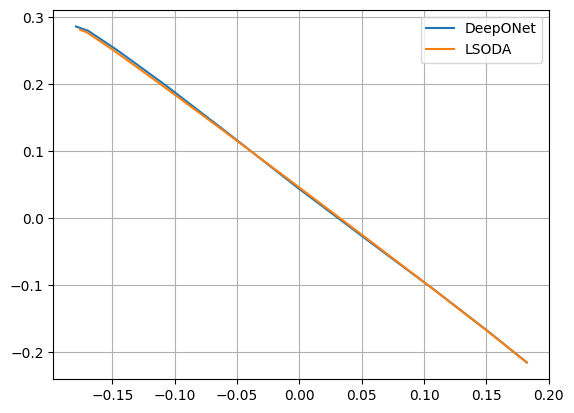

In [96]:
plt.plot(x1, x2)
plt.plot(x1rk, x2rk)

plt.grid()
plt.legend(['DeepONet','LSODA'])

Text(0.5, 1.0, 'Solution time series')

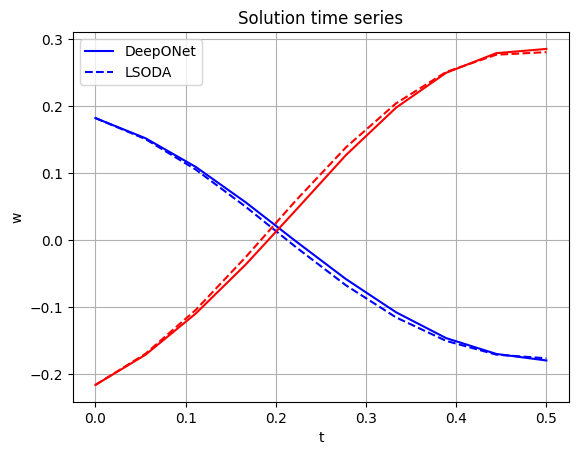

In [97]:
plt.plot(t, x1,'b')
plt.plot(t, x1rk,'b--')

plt.plot(t, x2, 'r')
plt.plot(t, x2rk, 'r--')

plt.legend(['DeepONet', 'LSODA'])
plt.grid()
plt.xlabel('t')
plt.ylabel('w')
plt.title('Solution time series')

Text(0.5, 1.0, 'Hamiltonian l2-error: 0.03479')

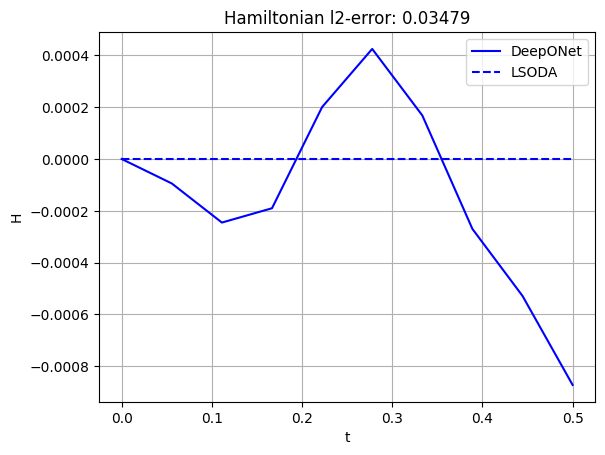

In [98]:
plt.plot(t, (H-H[0])/H[0],'b')
plt.plot(t, (Hrk-Hrk[0])/Hrk[0],'b--')

plt.legend(['DeepONet', 'LSODA'])
plt.grid()
plt.xlabel('t')
plt.ylabel('H')
plt.title(f'Hamiltonian l2-error: {np.linalg.norm((H-H[0])):2.5f}')

In [99]:
@jax.jit
def deriv_D(x, H_0) :

    x1 = x[0]
    x2 = x[1]
    y1 = x[2]
    y2 = x[3]

    A = l1*l2*(m1 + m2*(jnp.sin(x1 - x2)**2))
    h1 = (y1*y2*jnp.sin(x1 - x2))/A
    h2 = (m2*(l2**2)*(y1**2) + (m1 + m2)*(l1**2)*(y2**2) - 2*m2*l1*l2*y1*y2*jnp.cos(x1 - x2))/(2*A**2)

    H = (m2*l2**2*y1**2 + (m1+m2)*l1**2*y2**2 - 2*m2*l1*l2*y1*y2*jnp.cos(x1-x2))/(2*m2*l1**2*l2**2*(m1+m2*jnp.sin(x1-x2)**2))-(m1+m2)*grav*l1*jnp.cos(x1)-m2*grav*l2*jnp.cos(x2)

    dH_dx1 = (m1 + m2)*grav*l1*jnp.sin(x1) + h1 - h2*jnp.sin(2*(x1 - x2))
    dH_dx2 = m2*grav*l2*jnp.sin(x2) - h1 + h2*jnp.sin(2*(x1 - x2))
    dH_dy1 = (l2*y1 - l1*y2*jnp.cos(x1-x2))/(l1*A)
    dH_dy2 = (l1*(m1+m2)*y2 - m2*l2*y1*jnp.cos(x1-x2))/(m2*l2*A)

    dD_dx1 = 2*(H_0 - H)*-dH_dx1
    dD_dx2 = 2*(H_0 - H)*-dH_dx2
    dD_dy1 = 2*(H_0 - H)*-dH_dy1
    dD_dy2 = 2*(H_0 - H)*-dH_dy2
    
    deriv_D = jnp.array([dD_dx1, dD_dx2, dD_dy1, dD_dy2])
    deriv_D = jnp.reshape(deriv_D, (-1, 1))

    return deriv_D

In [100]:
@jax.jit
def func_D(x, H_0) :
 
    x1 = x[0]
    x2 = x[1]
    y1 = x[2]
    y2 = x[3]
   
    H = (m2*l2**2*y1**2 + (m1+m2)*l1**2*y2**2 - 2*m2*l1*l2*y1*y2*jnp.cos(x1-x2))/(2*m2*l1**2*l2**2*(m1+m2*jnp.sin(x1-x2)**2))-(m1+m2)*grav*l1*jnp.cos(x1)-m2*grav*l2*jnp.cos(x2)

    D = (H_0 - H)**2
    
    return D

In [101]:
@jax.jit
def find_rec(x):
    
    x = x + jnp.finfo(jnp.float64).eps
    return 1/x

In [102]:
@jax.jit
def wolfe_conds(args):

    alpha, curr_x, curr_f, curr_grad, next_x, next_f, next_grad, p, c1, c2, H_0, iter_num = args

    cond_1 = next_f - curr_f - c1*alpha*(curr_grad.T@p)
    cond_2 = next_grad.T@p - c2*(curr_grad.T@p)
    
    cond_1_bool = jax.lax.cond(cond_1[0][0] > 0.0 , lambda x: True, lambda x: False, None)
    cond_2_bool = jax.lax.cond(cond_2[0][0] < 0.0 , lambda x: True, lambda x: False, None)
    cond_3_bool = jax.lax.cond(alpha >= 1e-2 , lambda x: True, lambda x: False, None)

    wolfe_bool = jnp.logical_or(cond_1_bool, cond_2_bool)
    final_bool = jnp.logical_and(wolfe_bool, cond_3_bool)
    # final_bool = wolfe_bool
    
    return final_bool

In [103]:
@jax.jit
def update_alpha(args) :

    alpha, curr_x, curr_f, curr_grad, next_x, next_f, next_grad, p, c1, c2, H_0, iter_num = args

    alpha = alpha*0.1
    iter_num = iter_num + 1
        
    next_x = curr_x + alpha*p
    next_f = func_D(next_x, H_0)
    next_grad = deriv_D(next_x, H_0) 
   
    return (alpha, curr_x, curr_f, curr_grad, next_x, next_f, next_grad, p, c1, c2, H_0, iter_num)

In [104]:
@jax.jit
def BFGS(x, H_0) :

    x = jnp.reshape(x, (-1,1))
    x_0 = jnp.copy(x)

    iter_num = 0
    init_iter = 0
    alpha = 1.0
    c1 = 1e-4
    c2 = 0.9
    I_3 = jnp.identity(4, dtype = jnp.float64)
    B_0_inv = jnp.identity(4, dtype = jnp.float64)

    D_0 = func_D(x_0, H_0)
    gradD_0 = deriv_D(x_0, H_0)

    p = -1.0*alpha*(B_0_inv@gradD_0)

    # print(x_0, D_0, gradD_0)
    # input()

    next_x = x_0 + alpha*p
    next_D = func_D(next_x, H_0)
    next_gradD = deriv_D(next_x, H_0)

    # print(x_0, D_0, gradD_0, next_x, next_D, next_gradD, p)
    # input()

    init_args = (alpha, x_0, D_0, gradD_0, next_x, next_D, next_gradD, p, c1, c2, H_0, init_iter)
    
    step, _, _, _, _, _, _, _, _, _, _, _ = jax.lax.while_loop(wolfe_conds, update_alpha, init_args)

    x_1 = x_0 - step*(B_0_inv@gradD_0)

    while iter_num < 10:

        delta_x = x_1 - x_0

        D_1 = func_D(x_1, H_0)
        gradD_1 = deriv_D(x_1, H_0)

        y = gradD_1 - gradD_0       

        y_T_delta_x = y.T@delta_x
        
        y_T_delta_x_rec = find_rec(y_T_delta_x)
        
        B_1_inv = ((I_3 - (y_T_delta_x_rec*(delta_x@y.T)))@B_0_inv@(I_3 - (y_T_delta_x_rec*(y@delta_x.T)))) + (y_T_delta_x_rec*(delta_x@delta_x.T))   
        p = -1.0*alpha*(B_1_inv@gradD_1)
        
        next_x = x_1 + alpha*p
        next_D = func_D(next_x, H_0)
        next_gradD = deriv_D(next_x, H_0) 
                  
        init_args = (alpha, x_1, D_1, gradD_1, next_x, next_D, next_gradD, p, c1, c2, H_0, init_iter)

        step, _, _, _, _, _, _, _, _, _, _, _ = jax.lax.while_loop(wolfe_conds, update_alpha, init_args)

        x_next = x_1 - step*(B_1_inv@gradD_1)

        x_0 = x_1
        x_1 = x_next

        D_0 = D_1
        gradD_0 = gradD_1

        B_0_inv = B_1_inv
        
        iter_num = iter_num + 1


    return x_1

In [105]:
@jax.jit
def find_min_H(x, H_0) :

    return jax.vmap(BFGS, (0, 0), 0)(x, H_0)

In [106]:
z_vals = z
H_vals = z_init_H[:, 4:]

print(z_vals.shape, H_vals.shape)

(10, 4) (10, 1)


In [107]:
x_min = find_min_H(z_vals, H_vals)

x1_min = jnp.reshape(x_min[:,:1], (-1,))
x2_min = jnp.reshape(x_min[:,1:2], (-1,))
y1_min = jnp.reshape(x_min[:,2:3], (-1,))
y2_min = jnp.reshape(x_min[:,3:], (-1,))
H_min = (m2*l2**2*y1_min**2 + (m1+m2)*l1**2*y2_min**2 - 2*m2*l1*l2*y1_min*y2_min*np.cos(x1_min-x2_min))/(2*m2*l1**2*l2**2*(m1+m2*np.sin(x1_min-x2_min)**2))-(m1+m2)*grav*l1*np.cos(x1_min)-m2*grav*l2*np.cos(x2_min)



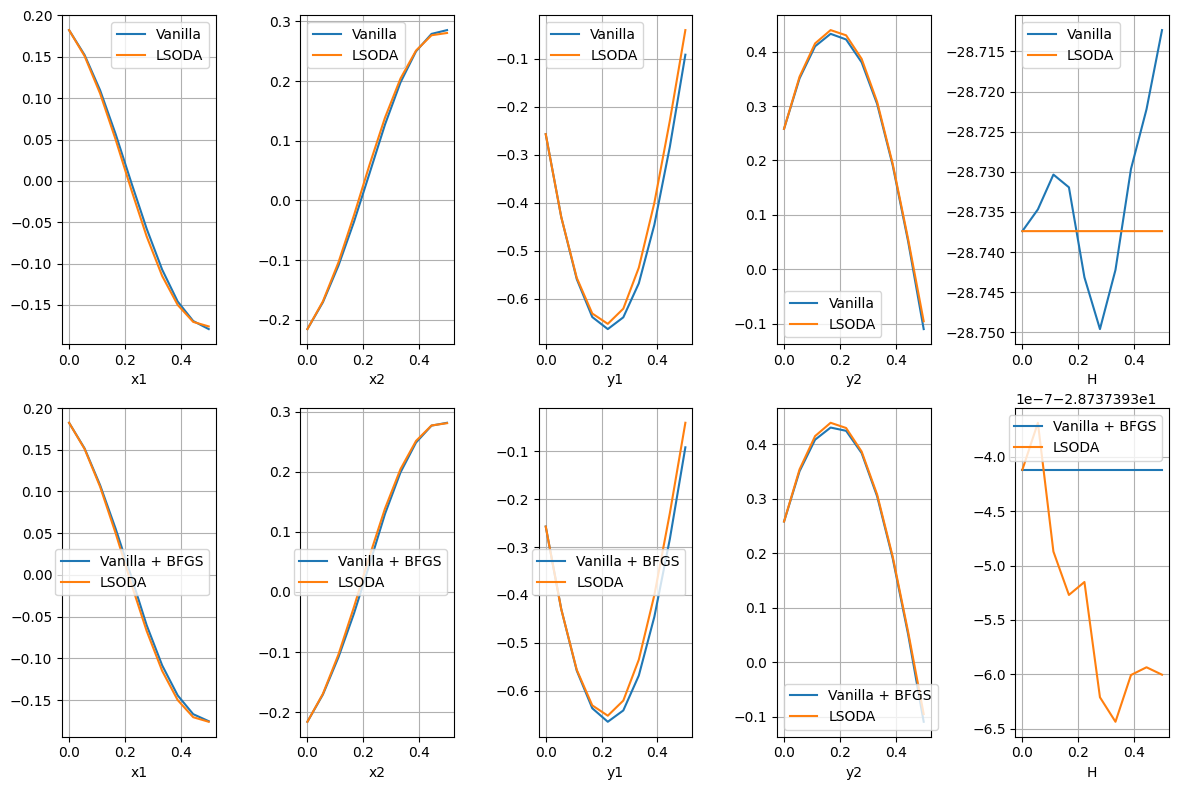

In [108]:
fig = plt.figure(figsize=(12, 8))

plt.subplot(2, 5, 1)
plt.tight_layout()
plt.plot(t, x1)
plt.plot(t, x1rk)
plt.xlabel("x1")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(2, 5, 2)
plt.tight_layout()
plt.plot(t, x2)
plt.plot(t, x2rk)
plt.xlabel("x2")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(2, 5, 3)
plt.tight_layout()
plt.plot(t, y1)
plt.plot(t, y1rk)
plt.xlabel("y1")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(2, 5, 4)
plt.tight_layout()
plt.plot(t, y2)
plt.plot(t, y2rk)
plt.xlabel("y2")
plt.grid()
plt.legend(['Vanilla','LSODA'])


plt.subplot(2, 5, 5)
plt.tight_layout()
plt.plot(t, H)
plt.plot(t, Hrk)
plt.xlabel("H")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(2, 5, 6)
plt.tight_layout()
plt.plot(t, x1_min)
plt.plot(t, x1rk)
plt.xlabel("x1")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(2, 5, 7)
plt.tight_layout()
plt.plot(t, x2_min)
plt.plot(t, x2rk)
plt.xlabel("x2")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(2, 5, 8)
plt.tight_layout()
plt.plot(t, y1_min)
plt.plot(t, y1rk)
plt.xlabel("y1")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(2, 5, 9)
plt.tight_layout()
plt.plot(t, y2_min)
plt.plot(t, y2rk)
plt.xlabel("y2")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(2, 5, 10)
plt.tight_layout()
plt.plot(t, H_min)
plt.plot(t, Hrk)
plt.xlabel("H")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])


plt.show()

In [109]:
class ClosestPoint(nn.Module):
    
    @nn.compact
    def __call__(self, inputs):

        x = inputs[0]
        H_0 = inputs[1]

        z_min = find_min_H(x, H_0)
    
        return z_min

In [110]:
class CDeepONet(nn.Module):

  t0: float
  tfinal: float
  layers: int
  units: int

  @nn.compact
  def __call__(self, t, z0):

    if z0.ndim == 1:
      z0 = jnp.reshape(z0, (1,-1))

    H_0 = z0[:, 4:]
    z0 = z0[:, :4]

    t = jnp.reshape(t, (-1,1))

    b = Normalize(self.t0, self.tfinal)(t)

    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(z0)

    trunk_x1 = trunk_net[:,:self.units]
    trunk_x2 = trunk_net[:,self.units:2*self.units]
    trunk_y1 = trunk_net[:,2*self.units:3*self.units]
    trunk_y2 = trunk_net[:,3*self.units:]

    branch_x1 = branch_net[:,:self.units]
    branch_x2 = branch_net[:,self.units:2*self.units]
    branch_y1 = branch_net[:,2*self.units:3*self.units]
    branch_y2 = branch_net[:,3*self.units:]

    x1 = CombineBranches()(trunk_x1, branch_x1)
    x2 = CombineBranches()(trunk_x2, branch_x2)
    y1 = CombineBranches()(trunk_y1, branch_y1)
    y2 = CombineBranches()(trunk_y2, branch_y2)

    x1 = HardConstraint(self.t0, self.tfinal, z0[:,:1])([t, x1])
    x2 = HardConstraint(self.t0, self.tfinal, z0[:,1:2])([t, x2])
    y1 = HardConstraint(self.t0, self.tfinal, z0[:,2:3])([t, y1])
    y2 = HardConstraint(self.t0, self.tfinal, z0[:,3:])([t, y2])

    z = jnp.column_stack([x1, x2, y1, y2])

    # z = ClosestPoint()([z, H_0])
      
    x1 = jnp.reshape(z[:,:1], (-1,))
    x2 = jnp.reshape(z[:,1:2], (-1,))
    y1 = jnp.reshape(z[:,2:3], (-1,))
    y2 = jnp.reshape(z[:,3:], (-1,))

    return x1, x2, y1, y2

In [117]:
Cdeeponet = CDeepONet(t0, tfinal, layers=4, units=units_num)

Cparams = Cdeeponet.init(jax.random.PRNGKey(0), jnp.ones((10,1)), jnp.ones((10,5)))

Cparams = copy.deepcopy(params)

Cparam_count = sum(x.size for x in jax.tree.leaves(Cparams))
print(Cparam_count)

1390


In [118]:
def flatten_pytree(params):
  values, tree_info = jax.tree_util.tree_flatten(params)

  no_leaves = len(values)
  shapes = []
  flattened = []

  for i in range(no_leaves):
    flattened.append(values[i].flatten())
    shapes.append(values[i].shape)

  return tree_info, shapes, jnp.concatenate(flattened)

def reconstruct_pytree(tree_info, shapes, flattened):

  values = []
  k = 0
  for i in range(len(shapes)):
    values.append(np.reshape(flattened[k:k+np.prod(shapes[i])], shapes[i]))
    k += np.prod(shapes[i])

  py_tree = jax.tree_util.tree_unflatten(tree_info, values)
  return py_tree

In [119]:
tree_info, shapes, Cparams_flat = flatten_pytree(Cparams)

In [120]:
@partial(jax.jit, static_argnums=(2,))
def cw_model(t, z, component, params):
  return Cdeeponet.apply(params, t, z)[component][0]

@partial(jax.jit, static_argnums=(2,))
def cw(t, z, component, params):
  return jax.vmap(cw_model, [0, 0, None, None])(t, z, component, params)

@partial(jax.jit, static_argnums=(2,))
def cw_t(t, z, component, params):
  return jax.vmap(jax.grad(cw_model, 0), [0, 0, None, None])(t, z, component, params)

@jax.jit
def closs(params, t, z):

    x1 = cw(t, z, 0, params)
    x2 = cw(t, z, 1, params)
    y1 = cw(t, z, 2, params)
    y2 = cw(t, z, 3, params)
    
    x1_t = cw_t(t, z, 0, params)
    x2_t = cw_t(t, z, 1, params)
    y1_t = cw_t(t, z, 2, params)
    y2_t = cw_t(t, z, 3, params)
      
    A = l1*l2*(m1 + m2*(jnp.sin(x1 - x2)**2))
    h1 = (y1*y2*jnp.sin(x1 - x2))/A
    h2 = (m2*(l2**2)*(y1**2) + (m1 + m2)*(l1**2)*(y2**2) - 2*m2*l1*l2*y1*y2*jnp.cos(x1 - x2))/(2*A**2)
    
    x1_t_loss = x1_t - (l2*y1 - l1*y2*jnp.cos(x1 - x2))/(l1*A)
    x2_t_loss = x2_t - (-m2*l2*y1*jnp.cos(x1 - x2) + l1*(m1 + m2)*y2)/(m2*l2*A)
    y1_t_loss = y1_t - (-(m1 + m2)*grav*l1*jnp.sin(x1) - h1 + h2*jnp.sin(2*(x1 - x2)))
    y2_t_loss = y2_t - (-m2*grav*l2*jnp.sin(x2) + h1 - h2*jnp.sin(2*(x1 - x2)))

    diff_loss = jnp.mean(x1_t_loss**2 + x2_t_loss**2 + y1_t_loss**2 + y2_t_loss**2)

    return diff_loss

@jax.jit
def ctrain_step(params, pdes, z):
    t = pdes[:,0]
    return jax.value_and_grad(closs)(params, t, z)

@partial(jax.jit, static_argnums=(3,))
def coptimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

@jax.jit
def cvalue_grad(params_flat, pdes, z):
    
    t = pdes[:,0]

    params_flat = jnp.reshape(params_flat, (-1,))
    params = reconstruct_pytree(tree_info, shapes, params_flat)    
    loss, grads = jax.value_and_grad(closs)(params, t, z)
    loss = jnp.array([[loss]])
    _, _, grads = flatten_pytree(grads)
    grads = jnp.reshape(grads, (-1, 1))
    
    return loss, grads

In [121]:
def ctrain_network(params, des, zsensor, epochs=100):

  N = de_points.shape[0]

  nr_batches = 1
  batch_size = len(des)//nr_batches

  lr = 1e-5
  optimizer = optax.adam(lr)
  opt_state = optimizer.init(params)

  ds_z = tf.data.Dataset.from_tensor_slices(zsensor)
  ds_de = tf.data.Dataset.from_tensor_slices(des)

  ds = tf.data.Dataset.zip((ds_de, ds_z))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.zeros(epochs)

  for i in range(epochs):

    for (des_batch, z_batch) in ds:
        
      loss, grads = ctrain_step(params, des_batch.numpy(), z_batch.numpy())
                   
      params, opt_state = coptimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    if i % 500 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [122]:
x1_sens = zsensors[:20, 0]
x2_sens = zsensors[:20, 1]
y1_sens = zsensors[:20, 2]
y2_sens = zsensors[:20, 3]
cde_points = de_points[:20, :]
H_sens = (m2*l2**2*y1_sens**2 + (m1+m2)*l1**2*y2_sens**2 - 2*m2*l1*l2*y1_sens*y2_sens*np.cos(x1_sens-x2_sens))/(2*m2*l1**2*l2**2*(m1+m2*np.sin(x1_sens-x2_sens)**2))-(m1+m2)*grav*l1*np.cos(x1_sens)-m2*grav*l2*np.cos(x2_sens)
czsensors = jnp.column_stack([x1_sens, x2_sens, y1_sens, y2_sens, H_sens])

print(cde_points.shape, czsensors.shape)

(20, 1) (20, 5)


In [123]:
epochs = 2500
Cparams, loss = ctrain_network(Cparams, de_points, czsensors, epochs)

Loss in epoch 0: 5.1997116373078204e-05
Loss in epoch 500: 1.0939120952545285e-05
Loss in epoch 1000: 5.872283057588419e-06
Loss in epoch 1500: 3.1429296043398955e-06
Loss in epoch 2000: 1.6827565442774557e-06


In [124]:
cx1 = jax.vmap(cw_model, [0, 0, None, None])(t, z_init_H, 0, params)
cx2 = jax.vmap(cw_model, [0, 0, None, None])(t, z_init_H, 1, params)
cy1 = jax.vmap(cw_model, [0, 0, None, None])(t, z_init_H, 2, params)
cy2 = jax.vmap(cw_model, [0, 0, None, None])(t, z_init_H, 3, params)

cH = (m2*l2**2*cy1**2 + (m1+m2)*l1**2*cy2**2 - 2*m2*l1*l2*cy1*cy2*np.cos(cx1-cx2))/(2*m2*l1**2*l2**2*(m1+m2*np.sin(cx1-cx2)**2))-(m1+m2)*grav*l1*np.cos(cx1)-m2*grav*l2*np.cos(cx2)

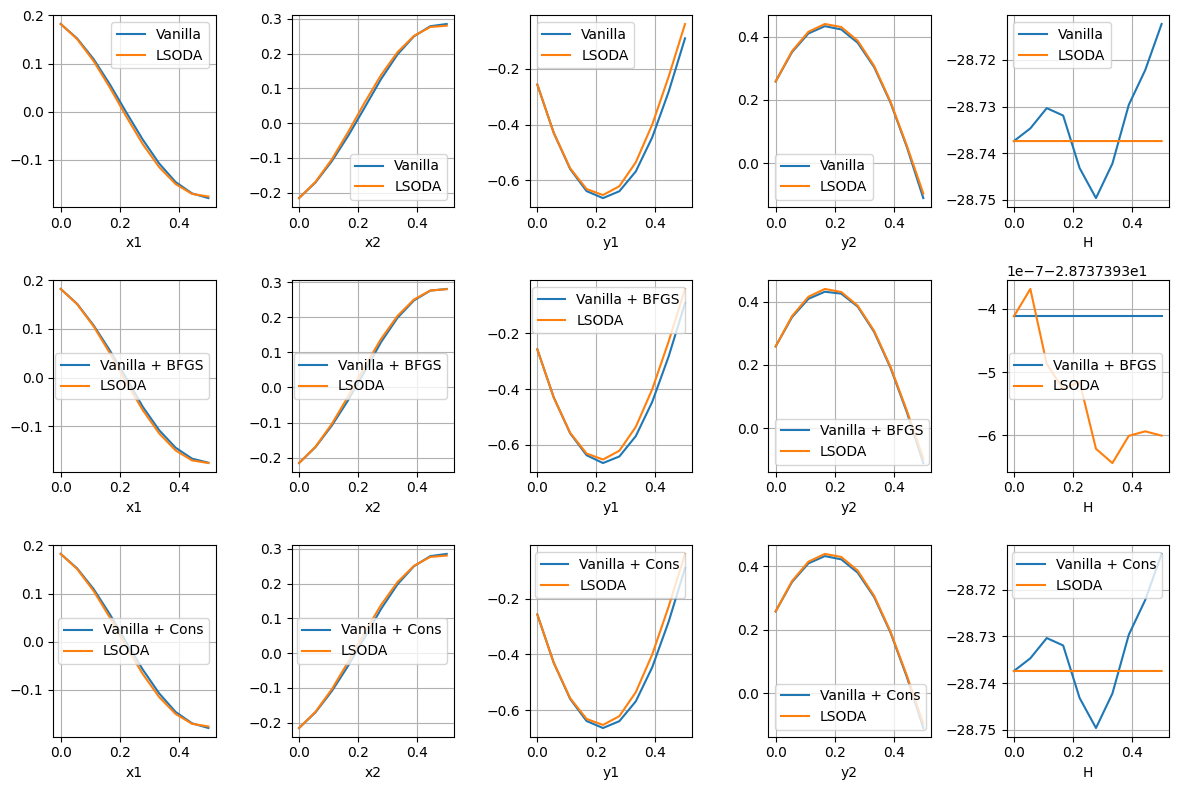

In [138]:
fig = plt.figure(figsize=(12, 8))

plt.subplot(3, 5, 1)
plt.tight_layout()
plt.plot(t, x1)
plt.plot(t, x1rk)
plt.xlabel("x1")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(3, 5, 2)
plt.tight_layout()
plt.plot(t, x2)
plt.plot(t, x2rk)
plt.xlabel("x2")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(3, 5, 3)
plt.tight_layout()
plt.plot(t, y1)
plt.plot(t, y1rk)
plt.xlabel("y1")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(3, 5, 4)
plt.tight_layout()
plt.plot(t, y2)
plt.plot(t, y2rk)
plt.xlabel("y2")
plt.grid()
plt.legend(['Vanilla','LSODA'])


plt.subplot(3, 5, 5)
plt.tight_layout()
plt.plot(t, H)
plt.plot(t, Hrk)
plt.xlabel("H")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(3, 5, 6)
plt.tight_layout()
plt.plot(t, x1_min)
plt.plot(t, x1rk)
plt.xlabel("x1")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 7)
plt.tight_layout()
plt.plot(t, x2_min)
plt.plot(t, x2rk)
plt.xlabel("x2")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 8)
plt.tight_layout()
plt.plot(t, y1_min)
plt.plot(t, y1rk)
plt.xlabel("y1")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 9)
plt.tight_layout()
plt.plot(t, y2_min)
plt.plot(t, y2rk)
plt.xlabel("y2")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 10)
plt.tight_layout()
plt.plot(t, H_min)
plt.plot(t, Hrk)
plt.xlabel("H")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 11)
plt.tight_layout()
plt.plot(t, cx1)
plt.plot(t, x1rk)
plt.xlabel("x1")
plt.grid()
plt.legend(['Vanilla + Cons','LSODA'])

plt.subplot(3, 5, 12)
plt.tight_layout()
plt.plot(t, cx2)
plt.plot(t, x2rk)
plt.xlabel("x2")
plt.grid()
plt.legend(['Vanilla + Cons','LSODA'])

plt.subplot(3, 5, 13)
plt.tight_layout()
plt.plot(t, cy1)
plt.plot(t, y1rk)
plt.xlabel("y1")
plt.grid()
plt.legend(['Vanilla + Cons','LSODA'])

plt.subplot(3, 5, 14)
plt.tight_layout()
plt.plot(t, cy2)
plt.plot(t, y2rk)
plt.xlabel("y2")
plt.grid()
plt.legend(['Vanilla + Cons','LSODA'])

plt.subplot(3, 5, 15)
plt.tight_layout()
plt.plot(t, cH)
plt.plot(t, Hrk)
plt.xlabel("H")
plt.grid()
plt.legend(['Vanilla + Cons','LSODA'])

plt.show()

In [139]:
@jax.jit
def wolfe_conds_params(args):

    c1 = 1e-4
    c2 = 0.9 

    alpha, x, loss, g, x_next, loss_next, g_next, p, init_iter, pdes, z = args

    cond_1 = loss_next - loss - c1*alpha*(g.T@p)
    cond_2 = g_next.T@p - c2*(g.T@p)
    
    cond_1_bool = jax.lax.cond(cond_1[0][0] > 0.0 , lambda x: True, lambda x: False, None)
    cond_2_bool = jax.lax.cond(cond_2[0][0] < 0.0 , lambda x: True, lambda x: False, None)
    cond_3_bool = jax.lax.cond(alpha >= 1e-12 , lambda x: True, lambda x: False, None)

    wolfe_bool = jnp.logical_or(cond_1_bool, False)
    final_bool = jnp.logical_and(wolfe_bool, True)
    
    return final_bool

In [140]:
@jax.jit
def update_alpha_params(args) :

    k = 0.1

    alpha, x, loss, g, x_next, loss_next, g_next, p, init_iter, pdes, z = args

    alpha = alpha*k
    init_iter = init_iter + 1
        
    x_next = x + alpha*p
    loss_next, g_next = cvalue_grad(x_next, pdes, z)
       
    return (alpha, x, loss, g, x_next, loss_next, g_next, p, init_iter, pdes, z)

In [141]:
indices_list = jnp.array([i for i in range(Cparam_count)])
print(len(indices_list))

1390


In [142]:
#@jax.jit
def bfgs_params(params_flat, pdes, z) :

    losses = []
    iter_num = 0
    iter_init = 0
    alpha = 1.0

    x_init = jnp.reshape(params_flat, (-1, 1))
    loss_init, g_init = cvalue_grad(x_init, pdes, z)
    
    losses.append(loss_init[0][0])

    p_init = -g_init
    
    x_pot = x_init + alpha*p_init
    loss_pot, g_pot = cvalue_grad(x_pot, pdes, z)

    init_args = (alpha, x_init, loss_init, g_init, x_pot, loss_pot, g_pot, p_init, iter_init, pdes, z)

    step, _, _, _, _, _, _, _, _, _, _ = jax.lax.while_loop(wolfe_conds_params, update_alpha_params, init_args)

    x_next = x_init + step*p_init
    
    loss = loss_init
    x = x_init
    g = g_init
    
    while iter_num < 100:

        # print(iter_num)

        delta_x = x_next - x
        
        loss_next, g_next = cvalue_grad(x_next, pdes, z)
        
        losses.append(loss_next[0][0])
        
        y = g_next - g

        y_T_delta_x = y.T@delta_x
        y_T_delta_x_rec = find_rec(y_T_delta_x)

        term_1 = y_T_delta_x_rec*(delta_x@y.T)
        term_2 = y_T_delta_x_rec*(y@delta_x.T)
        term_3 = y_T_delta_x_rec*(delta_x@delta_x.T)

        if iter_num == 0 :

            term_1 = term_1.at[indices_list, indices_list].set(1.0 - term_1[indices_list, indices_list])
            term_2 = term_2.at[indices_list, indices_list].set(1.0 - term_2[indices_list, indices_list])
        
            H_next = term_1@term_2 + term_3

        else :

            term_1 = term_1.at[indices_list, indices_list].set(1.0 - term_1[indices_list, indices_list])
            term_2 = term_2.at[indices_list, indices_list].set(1.0 - term_2[indices_list, indices_list])
        
            H_next = term_1@H@term_2 + term_3

        p = -H_next@g_next

        x_pot = x_next + alpha*p
        loss_pot, g_pot = cvalue_grad(x_pot, pdes, z)
                  
        init_args = (alpha, x_next, loss_next, g_next, x_pot, loss_pot, g_pot, p, iter_init, pdes, z)
    
        step, _, _, _, _, _, _, _, _, _, _ = jax.lax.while_loop(wolfe_conds_params, update_alpha_params, init_args)

        x_temp = x_next + step*p

        x = x_next
        x_next = x_temp

        loss = loss_next
        g = g_next
        H = H_next
        
        iter_num = iter_num + 1

        if iter_num % 10 == 0:
          print(f'Iteration: {iter_num}, Loss: {losses[-1]}')


    loss_final, _ = cvalue_grad(x_next, pdes, z)
    losses.append(loss_final[0][0])
    
    return x_next, losses

In [143]:
Cparams_flat, loss_bfgs = bfgs_params(Cparams_flat, cde_points, czsensors)

Iteration: 10, Loss: 0.019644961471120825
Iteration: 20, Loss: 0.019644423449660126
Iteration: 30, Loss: 0.019643515450223508
Iteration: 40, Loss: 0.019642978743089373
Iteration: 50, Loss: 0.01964252440502567
Iteration: 60, Loss: 0.01964198942103682
Iteration: 70, Loss: 0.019641759425417717
Iteration: 80, Loss: 0.019641498475858752
Iteration: 90, Loss: 0.019641228000043483
Iteration: 100, Loss: 0.019641106088998883


In [144]:
Cparams = reconstruct_pytree(tree_info, shapes, Cparams_flat)

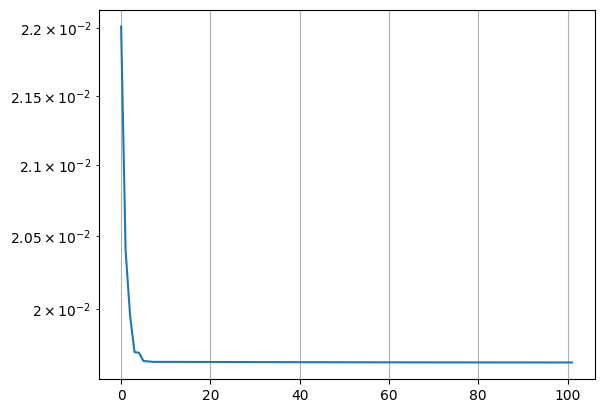

In [145]:
plt.semilogy(loss_bfgs)
plt.grid()

In [146]:
cx1 = jax.vmap(cw_model, [0, 0, None, None])(t, z_init_H, 0, Cparams)
cx2 = jax.vmap(cw_model, [0, 0, None, None])(t, z_init_H, 1, Cparams)
cy1 = jax.vmap(cw_model, [0, 0, None, None])(t, z_init_H, 2, Cparams)
cy2 = jax.vmap(cw_model, [0, 0, None, None])(t, z_init_H, 3, Cparams)

cH = (m2*l2**2*cy1**2 + (m1+m2)*l1**2*cy2**2 - 2*m2*l1*l2*cy1*cy2*np.cos(cx1-cx2))/(2*m2*l1**2*l2**2*(m1+m2*np.sin(cx1-cx2)**2))-(m1+m2)*grav*l1*np.cos(cx1)-m2*grav*l2*np.cos(cx2)

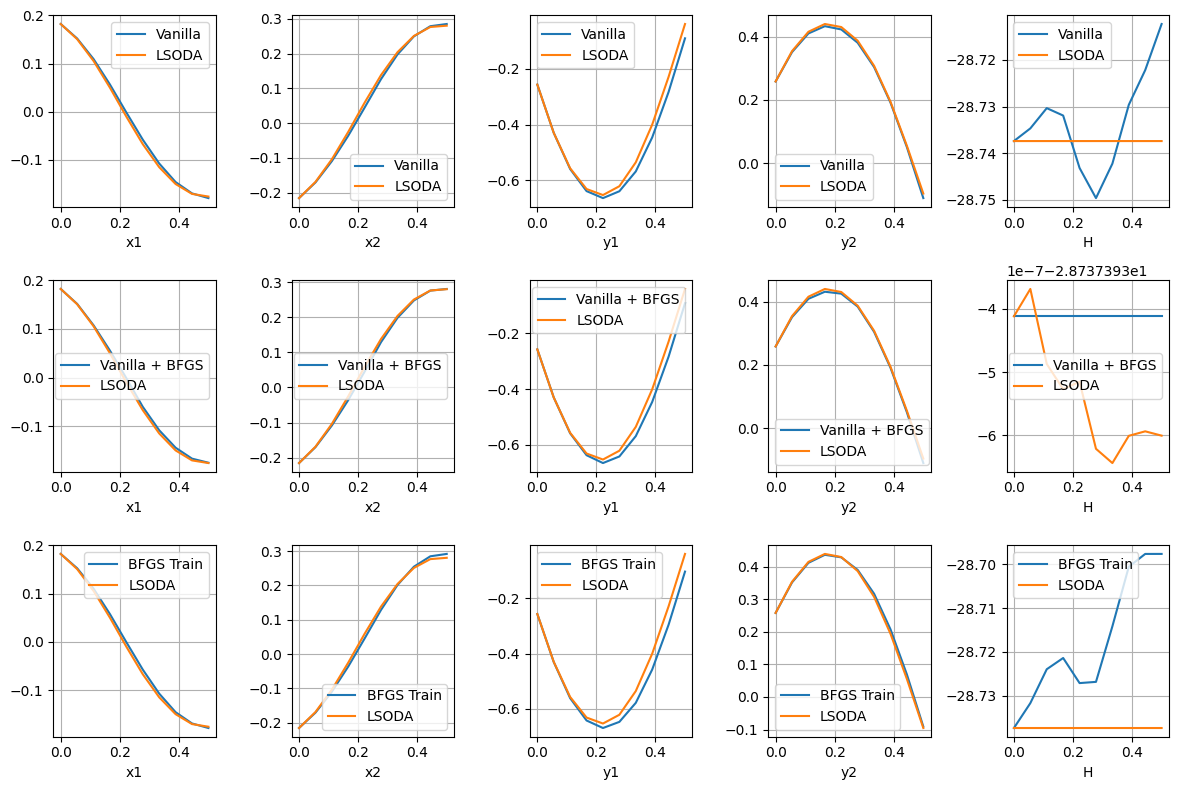

In [147]:
fig = plt.figure(figsize=(12, 8))

plt.subplot(3, 5, 1)
plt.tight_layout()
plt.plot(t, x1)
plt.plot(t, x1rk)
plt.xlabel("x1")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(3, 5, 2)
plt.tight_layout()
plt.plot(t, x2)
plt.plot(t, x2rk)
plt.xlabel("x2")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(3, 5, 3)
plt.tight_layout()
plt.plot(t, y1)
plt.plot(t, y1rk)
plt.xlabel("y1")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(3, 5, 4)
plt.tight_layout()
plt.plot(t, y2)
plt.plot(t, y2rk)
plt.xlabel("y2")
plt.grid()
plt.legend(['Vanilla','LSODA'])


plt.subplot(3, 5, 5)
plt.tight_layout()
plt.plot(t, H)
plt.plot(t, Hrk)
plt.xlabel("H")
plt.grid()
plt.legend(['Vanilla','LSODA'])

plt.subplot(3, 5, 6)
plt.tight_layout()
plt.plot(t, x1_min)
plt.plot(t, x1rk)
plt.xlabel("x1")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 7)
plt.tight_layout()
plt.plot(t, x2_min)
plt.plot(t, x2rk)
plt.xlabel("x2")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 8)
plt.tight_layout()
plt.plot(t, y1_min)
plt.plot(t, y1rk)
plt.xlabel("y1")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 9)
plt.tight_layout()
plt.plot(t, y2_min)
plt.plot(t, y2rk)
plt.xlabel("y2")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 10)
plt.tight_layout()
plt.plot(t, H_min)
plt.plot(t, Hrk)
plt.xlabel("H")
plt.grid()
plt.legend(['Vanilla + BFGS','LSODA'])

plt.subplot(3, 5, 11)
plt.tight_layout()
plt.plot(t, cx1)
plt.plot(t, x1rk)
plt.xlabel("x1")
plt.grid()
plt.legend(['BFGS Train','LSODA'])

plt.subplot(3, 5, 12)
plt.tight_layout()
plt.plot(t, cx2)
plt.plot(t, x2rk)
plt.xlabel("x2")
plt.grid()
plt.legend(['BFGS Train','LSODA'])

plt.subplot(3, 5, 13)
plt.tight_layout()
plt.plot(t, cy1)
plt.plot(t, y1rk)
plt.xlabel("y1")
plt.grid()
plt.legend(['BFGS Train','LSODA'])

plt.subplot(3, 5, 14)
plt.tight_layout()
plt.plot(t, cy2)
plt.plot(t, y2rk)
plt.xlabel("y2")
plt.grid()
plt.legend(['BFGS Train','LSODA'])

plt.subplot(3, 5, 15)
plt.tight_layout()
plt.plot(t, cH)
plt.plot(t, Hrk)
plt.xlabel("H")
plt.grid()
plt.legend(['BFGS Train','LSODA'])

plt.show()